# BigBird: Transformers for Longer Sequences

### Architecture, Sparse Attention, Computational Complexity, and Applications

**Research topic:** BigBird — Transformers for Longer Sequences  
**Main paper:** Zaheer et al., NeurIPS 2020

## Abstract

Transformers have achieved strong results in natural language processing, but standard self-attention becomes computationally expensive as the input sequence grows. This makes it difficult to process long documents without truncating them or dividing them into smaller pieces.

BigBird addresses this limitation by replacing full self-attention with a carefully designed **sparse attention mechanism**. It combines local attention, random attention, and global attention to reduce the attention mechanism's quadratic dependence on sequence length to linear scaling under fixed sparsity settings.







## 1. Paper Main idea 

The main contribution is an attention mechanism designed to process much longer input sequences more efficiently than standard full attention.

BigBird's key idea is not to connect every token directly to every other token. Instead, it uses a structured set of connections that allows information to move through local neighborhoods, random connections, and global tokens.

**Original paper:** https://arxiv.org/abs/2007.14062


## 2. Motivation: Why Do We Need BigBird?

A Transformer processes a sequence of tokens, such as the words in a sentence or a document. In self-attention, each token can gather information from other tokens.

In standard full self-attention, every token attends to every token in the input sequence.

For a sequence of length $n$, the attention score matrix contains $n \times n$ entries. Therefore, the number of attention scores grows quadratically:

$$
\text{Attention score count} = n^2
$$

For example:

* 512 tokens require $512^2 = 262{,}144$ attention scores per attention head.
* 1,024 tokens require $1024^2 = 1{,}048{,}576$ scores per head.
* 2,048 tokens require $2048^2 = 4{,}194{,}304$ scores per head.
* 4,096 tokens require $4096^2 = 16{,}777{,}216$ scores per head.

Doubling the sequence length approximately quadruples the number of attention scores.

This creates a significant computational and memory challenge when processing long research papers, reports, books, or other large documents.

### The limitation

A model may have to truncate a document or split it into chunks because processing the entire document at once is too expensive. This can be problematic when important information is distributed across different sections.

### BigBird's motivation

BigBird aims to preserve useful information

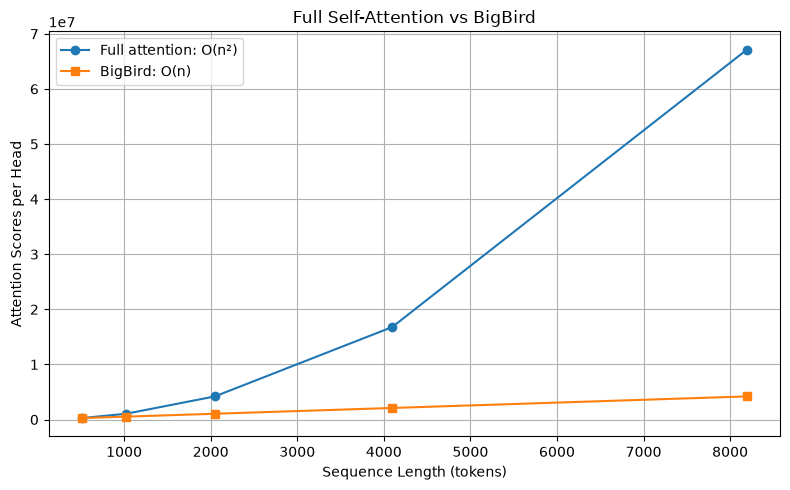

In [4]:
import pandas as pd
import matplotlib.pyplot as plt

sequence_lengths = [512, 1024, 2048, 4096, 8192]
keys_per_token = 512  # window + random + global keys each token attends to

plt.figure(figsize=(8, 5))

plt.plot(
    sequence_lengths,
    [n**2 for n in sequence_lengths],
    marker="o",
    label="Full attention: O(n²)"
)

plt.plot(
    sequence_lengths,
    [n * keys_per_token for n in sequence_lengths],
    marker="s",
    label="BigBird: O(n)"
)

plt.xlabel("Sequence Length (tokens)")
plt.ylabel("Attention Scores per Head")
plt.title("Full Self-Attention vs BigBird")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

## 3. BigBird Architecture

BigBird changes the attention connections inside the Transformer. Rather than calculating all possible token-to-token connections, it uses three complementary patterns:

1. **Local or window attention:** connects each token to nearby tokens.
2. **Random attention:** gives tokens additional connections to selected distant tokens.
3. **Global attention:** allows designated global tokens to attend to the whole sequence, while all tokens can attend to those global tokens.

These patterns work together to balance local context, long-distance information flow, and sequence-wide communication.

The objective is to reduce unnecessary attention calculations without losing the ability to model important relationships across a long input.


## 4. Visualizing the Attention Patterns

**![ BigBird arch. Idea](birdarch.png)**

The figure illustrates four patterns:

- (a) Random attention
- (b) Window attention
- (c) Global attention
- (d) The combined BigBird pattern


## 5. Component One: Local Attention

Local attention, also called window attention, allows each token to attend to tokens within a nearby window.

For example, consider:

When processing the token "analyzed," local attention helps the model use nearby information such as "carefully" and "the researcher."

### Why is it useful?

Natural language contains many local relationships. Neighboring words often help determine meaning, grammatical structure, and context.


## 6. Component Two: Random Attention

Random attention adds connections between tokens that are not necessarily close to one another.

Imagine that a document discusses a research problem in the introduction and presents the relevant result near the end. Local attention alone does not provide a direct connection between those distant positions in one attention layer.

Random attention introduces additional routes for information to travel between distant parts of the sequence.

### Why is it useful?

- It creates shortcuts between distant tokens.
- It reduces the dependence on local connections alone.
- Across multiple layers, it helps information move through the sequence more efficiently.


## 7. Component Three: Global Attention

Global attention allows selected global tokens to interact with the entire sequence.

A global token can attend to all tokens, and all tokens can attend to the global token.

This creates a communication hub that can help information move across distant positions.

### Example

Suppose a document contains 5,000 tokens. A token near the beginning may need information from the conclusion.

With a global token, information can potentially travel through a route such as:

**Token near the beginning → global token → token near the conclusion**

This is a conceptual illustration of information flow across layers, not a guarantee that every piece of information is fully transmitted in a single step.

### Why is it useful?

- It enables sequence-wide communication.
- It provides a route for gathering information from different parts of a document.
- It supports tasks where the model must combine information from multiple sections.

The precise choice and number of global tokens depend on the BigBird variant and implementation.

## 8. Block-Sparse Attention: How the Pattern Is Implemented

So far, the visualizations have shown individual token connections. BigBird's implementation also groups tokens into blocks.

For example, with a block size of 64, consecutive tokens are grouped into blocks of 64 tokens each.

Instead of selecting individual token connections independently, the implementation organizes many attention connections around groups of tokens. This allows it to compute selected blocks of attention scores and skip blocks that are not required by the sparse pattern.

### Example

If a sequence contains 1,024 tokens and the block size is 64:

$$
\text{Number of blocks} = \frac{1024}{64} = 16
$$

Full attention would consider all $16 \times 16$ block pairs. A block-sparse pattern computes only the selected block pairs.

Each selected block pair still contains token-level attention calculations within that block. Block sparsity does not mean that each block is treated as one word or one token.

### Why use blocks?

Modern GPUs and TPUs are efficient at processing contiguous groups of data. Organizing sparse attention around blocks can make it more practical than performing many small, irregular token-level operations.

The Hugging Face BigBird configuration documents a default block size of 64 and three random blocks. These are implementation defaults, not universal requirements for all BigBird implementations.


**Reference:** [Hugging Face BigBird documentation](https://huggingface.co/docs/transformers/en/model_doc/big_bird)

## 9. Computational Complexity: BERT vs. BigBird vs. Longformer

Computational complexity describes how the amount of work grows as the input sequence becomes longer.

Let:

- $n$ = number of tokens in the input sequence.
- $w$ = number of local tokens or the size of the local attention window.
- $r$ = number of random attention connections per token.
- $g$ = number of global tokens or global connections, depending on the pattern.

### BERT: Full self-attention

Standard BERT uses full self-attention in its encoder. Every token can attend to every token.

The attention score matrix contains $n^2$ entries, so the attention score memory scales as:

$$
O(n^2)
$$

The attention computation itself is commonly expressed as $O(n^2d)$, where $d$ is the hidden dimension, excluding other model operations.

### BigBird: Sparse self-attention

BigBird uses local, random, and global attention. When the local window, random connections, and number of global tokens remain bounded as the sequence grows, the number of selected attention connections scales linearly:

$$
O\big(n(w+r+g)\big) = O(n)
$$

This refers to the sparse attention component, not every operation in the entire Transformer.

### Longformer: Local plus global attention

Longformer also targets linear scaling by combining sliding-window local attention with task-selected global attention.

For a fixed local window and a bounded number of global tokens, its attention cost also scales linearly with sequence length.

### Main distinction

BigBird adds random attention connections to local and global attention. Longformer's main sparse pattern uses local window attention and selected global attention.

Both are designed to process long documents more efficiently than standard full attention.

## 10. Suitable Applications of BigBird

BigBird is especially useful when relevant information may be distributed across a long input.

### 1. Long-document question answering

A question may depend on evidence found in several paragraphs or sections. A longer input context can reduce the need to discard relevant parts of the document.

### 2. Document classification

Examples include classifying long reports, legal documents, scientific papers, and other documents whose meaning cannot be captured reliably from a small excerpt.

### 3. Document summarization

Long-document summarization requires a model to identify important information across a large source document. BigBird's sparse encoder can help process longer inputs. Encoder-decoder models such as BigBird-Pegasus were developed for summarization.

### 4. Scientific and genomic sequence analysis

The original paper also investigated genomic sequences, including promoter prediction and chromatin-profile prediction. These tasks benefit from representing relationships across longer biological sequences.

### 5. Other long-context NLP tasks

BigBird may be useful for information extraction and other document-level tasks when the relevant context exceeds the practical input limit of standard full-attention models.

**Important:** BigBird is not automatically the best model for every long-context task. Its usefulness depends on the input length, task, checkpoint, data, and computational environment.

## 11. Limitations and Trade-offs

1. **Not every token pair connects directly:** Some relationships available in full attention are absent from a particular sparse attention layer.
2. **Pattern and configuration matter:** The local window, random connections, global-token placement, and sequence length influence performance.
3. **Sparse attention is not free:** The model still performs attention calculations, feed-forward operations, and other Transformer computations.
4. **Implementation affects real performance:** An inefficient sparse implementation may fail to deliver the theoretical speed or memory improvements.
5. **Short sequences may not benefit:** Sparse-attention overhead can make it less attractive when the input is relatively short. Hugging Face documents a recommendation to use full attention for sequences shorter than 1,024 tokens in its implementation.
6. **Longer context is not automatically better:** The model must still learn to identify useful information from the input.
7. **Results depend on the task:** A model that performs well on one benchmark may not be best for another.


## 12. Conclusion

BigBird is a Transformer architecture designed to overcome the computational limitations of full self-attention on long input sequences.

Its main innovation is a sparse attention mechanism that combines:

- **Local attention** for nearby context.
- **Random attention** for connections between distant positions.
- **Global attention** for sequence-wide information flow.

Its block-sparse implementation organizes selected attention connections into groups of tokens, helping make sparse computation practical.

Compared with standard BERT full attention, BigBird reduces the attention component's theoretical scaling from quadratic to linear when its sparsity settings remain bounded. Longformer achieves linear scaling as well, using a primarily local-plus-global attention pattern.

BigBird is a useful option for long-document question answering, summarization, classification, and some genomic sequence tasks. However, its practical benefits depend on the task, implementation, model configuration, and available hardware.

**Final takeaway:** BigBird does not connect every token to every other token. It uses a carefully designed sparse pattern to preserve useful information flow while reducing the cost of processing long sequences.

## 13. References

1. Zaheer, M., Guruganesh, G., Dubey, A., et al. (2020). **Big Bird: Transformers for Longer Sequences.** Advances in Neural Information Processing Systems (NeurIPS 2020).  
   https://arxiv.org/abs/2007.14062

2. Beltagy, I., Peters, M. E., & Cohan, A. (2020). **Longformer: The Long-Document Transformer.**  
   https://arxiv.org/abs/2004.05150

3. Hugging Face. **BigBird documentation.** Configuration, attention types, block size, and random blocks.  
   https://huggingface.co/docs/transformers/en/model_doc/big_bird

4. Google Research. **Constructing Transformers for Longer Sequences with Sparse Attention Methods.**  
   https://research.google/blog/constructing-transformers-for-longer-sequences-with-sparse-attention-methods/

5. Devlin, J., Chang, M.-W., Lee, K., & Toutanova, K. (2019). **BERT: Pre-training of Deep Bidirectional Transformers for Language Understanding.**  
   https://arxiv.org/abs/1810.04805